In [11]:
# Importing the required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import joblib
import warnings

warnings.filterwarnings('ignore')

# Importing libraries for machine learning
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.multiclass import OneVsRestClassifier

# Importing the three machine learning algorithms
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier

# Importing evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

print("All libraries imported successfully!")

All libraries imported successfully!


In [12]:
# Uploading the movie dataset

from google.colab import files

uploaded = files.upload()

file_name = list(uploaded.keys())[0]

print("Uploaded file:", file_name)

# Reading the dataset
try:
    df = pd.read_csv(file_name)
except:
    df = pd.read_excel(file_name)

# Displaying the first five rows
df.head()

Saving Movie_Predictor_Dataset.csv.xls to Movie_Predictor_Dataset.csv.xls
Uploaded file: Movie_Predictor_Dataset.csv.xls


,Unnamed: 0,movie_id,movie_name,year,genre,overview,director,cast
0,0,tt15354916,Jawan,2023,"Action, Thriller",A high-octane action thriller which outlines t...,Atlee,"Shah Rukh Khan, Nayanthara, Vijay Sethupathi, ..."
1,1,tt15748830,Jaane Jaan,2023,"Crime, Drama, Mystery",A single mother and her daughter who commit a ...,Sujoy Ghosh,"Kareena Kapoor, Jaideep Ahlawat, Vijay Varma, ..."
2,2,tt11663228,Jailer,2023,"Action, Comedy, Crime",A retired jailer goes on a manhunt to find his...,Nelson Dilipkumar,"Rajinikanth, Mohanlal, Shivarajkumar, Jackie S..."
3,3,tt14993250,Rocky Aur Rani Kii Prem Kahaani,2023,"Comedy, Drama, Family",Flamboyant Punjabi Rocky and intellectual Beng...,Karan Johar,"Ranveer Singh, Alia Bhatt, Dharmendra, Shabana..."
4,4,tt15732324,OMG 2,2023,"Comedy, Drama",An unhappy civilian asks the court to mandate ...,Amit Rai,"Pankaj Tripathi, Akshay Kumar, Yami Gautam, Pa..."


In [13]:
# Checking the number of rows and columns

print("Dataset Shape:", df.shape)

# Checking all column names
print("\nColumn Names:")
print(df.columns)

# Checking information about the dataset
print("\nDataset Information:")
df.info()

# Checking missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Checking duplicate records
print("\nDuplicate Records:", df.duplicated().sum())

Dataset Shape: (2199, 8)

Column Names:
Index(['Unnamed: 0', 'movie_id', 'movie_name', 'year', 'genre', 'overview',
       'director', 'cast'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2199 entries, 0 to 2198
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Unnamed: 0  2199 non-null   int64 
 1   movie_id    2199 non-null   object
 2   movie_name  2199 non-null   object
 3   year        2134 non-null   object
 4   genre       2199 non-null   object
 5   overview    2199 non-null   object
 6   director    2199 non-null   object
 7   cast        2199 non-null   object
dtypes: int64(1), object(7)
memory usage: 137.6+ KB

Missing Values:
Unnamed: 0     0
movie_id       0
movie_name     0
year          65
genre          0
overview       0
director       0
cast           0
dtype: int64

Duplicate Records: 0


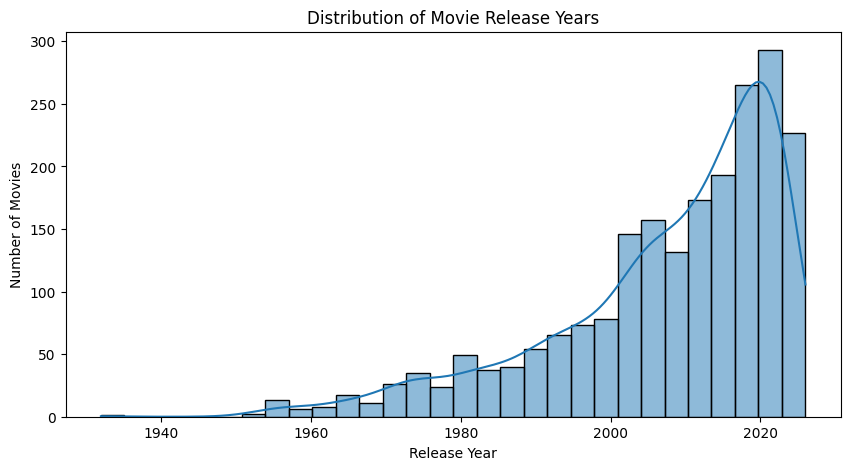

In [14]:
# Displaying the distribution of movie release years

# Checking if year column is available
if 'year' in df.columns:

    df['year'] = pd.to_numeric(df['year'], errors='coerce')

    plt.figure(figsize=(10, 5))
    sns.histplot(df['year'].dropna(), bins=30, kde=True)

    plt.title("Distribution of Movie Release Years")
    plt.xlabel("Release Year")
    plt.ylabel("Number of Movies")
    plt.show()

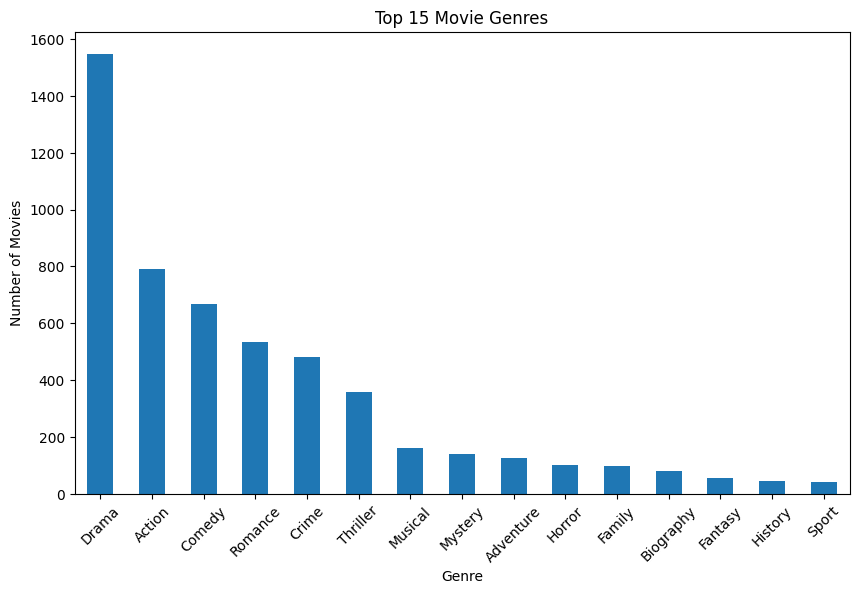

In [15]:
# Checking the most common movie genres

genre_counts = df['genre'].dropna().str.split(',').explode().str.strip()

plt.figure(figsize=(10, 6))

genre_counts.value_counts().head(15).plot(kind='bar')

plt.title("Top 15 Movie Genres")
plt.xlabel("Genre")
plt.ylabel("Number of Movies")
plt.xticks(rotation=45)
plt.show()

In [16]:
# Removing unnecessary columns if present

df.columns = df.columns.str.strip().str.lower()

df = df.loc[:, ~df.columns.str.contains('^unnamed')]

# Keeping only the columns required for our project
df = df[['overview', 'genre']].copy()

# Removing duplicate records
df.drop_duplicates(inplace=True)

# Removing rows where overview or genre is missing
df.dropna(subset=['overview', 'genre'], inplace=True)

# Converting text into string format
df['overview'] = df['overview'].astype(str)
df['genre'] = df['genre'].astype(str)

# Removing empty descriptions
df = df[
    (df['overview'].str.strip() != '') &
    (df['genre'].str.strip() != '')
]

print("Dataset after cleaning:", df.shape)

df.head()

Dataset after cleaning: (2149, 2)


,overview,genre
0,A high-octane action thriller which outlines t...,"Action, Thriller"
1,A single mother and her daughter who commit a ...,"Crime, Drama, Mystery"
2,A retired jailer goes on a manhunt to find his...,"Action, Comedy, Crime"
3,Flamboyant Punjabi Rocky and intellectual Beng...,"Comedy, Drama, Family"
4,An unhappy civilian asks the court to mandate ...,"Comedy, Drama"


In [17]:
# Creating a function to clean movie descriptions

def clean_text(text):

    # Converting text into lowercase
    text = text.lower()

    # Removing special characters and numbers
    text = re.sub(r'[^a-z\s]', ' ', text)

    # Removing extra spaces
    text = re.sub(r'\s+', ' ', text)

    return text.strip()


# Applying the cleaning function
df['overview'] = df['overview'].apply(clean_text)

print("Text cleaning completed!")

df[['overview', 'genre']].head()

Text cleaning completed!


,overview,genre
0,a high octane action thriller which outlines t...,"Action, Thriller"
1,a single mother and her daughter who commit a ...,"Crime, Drama, Mystery"
2,a retired jailer goes on a manhunt to find his...,"Action, Comedy, Crime"
3,flamboyant punjabi rocky and intellectual beng...,"Comedy, Drama, Family"
4,an unhappy civilian asks the court to mandate ...,"Comedy, Drama"


In [18]:
# Splitting multiple genres into a list

df['genre_list'] = df['genre'].apply(
    lambda x: [g.strip() for g in re.split(r'[,|]', x) if g.strip()]
)

# Counting how many times each genre appears
all_genres = df['genre_list'].explode()

genre_frequency = all_genres.value_counts()

print("Genre Frequency:")
print(genre_frequency)

Genre Frequency:
genre_list
Drama        1534
Action        785
Comedy        665
Romance       533
Crime         483
Thriller      349
Musical       163
Mystery       140
Adventure     125
Horror         99
Family         99
Biography      81
Fantasy        55
History        46
Sport          41
Music          24
Sci-Fi         21
Animation      17
War            17
Name: count, dtype: int64


In [19]:
# Keeping genres that have at least 20 movie examples

valid_genres = genre_frequency[genre_frequency >= 20].index.tolist()

# Keeping only the selected genres
df['genre_list'] = df['genre_list'].apply(
    lambda genres: [g for g in genres if g in valid_genres]
)

# Removing rows without any selected genre
df = df[df['genre_list'].apply(len) > 0].copy()

print("Final Dataset Shape:", df.shape)
print("Number of selected genres:", len(valid_genres))

Final Dataset Shape: (2143, 3)
Number of selected genres: 17


In [20]:
# Converting genre labels into numerical format

mlb = MultiLabelBinarizer()

Y = mlb.fit_transform(df['genre_list'])

# Movie overview will be our input feature
X = df['overview']

# Displaying all genre classes
print("Genre Classes:")
print(mlb.classes_)

print("\nInput Shape:", X.shape)
print("Output Shape:", Y.shape)

Genre Classes:
['Action' 'Adventure' 'Biography' 'Comedy' 'Crime' 'Drama' 'Family'
 'Fantasy' 'History' 'Horror' 'Music' 'Musical' 'Mystery' 'Romance'
 'Sci-Fi' 'Sport' 'Thriller']

Input Shape: (2143,)
Output Shape: (2143, 17)


In [21]:
# Splitting the data into training, validation and testing sets

# First separating 70% training data and 30% remaining data
X_train, X_temp, y_train, y_temp = train_test_split(
    X, Y,
    test_size=0.30,
    random_state=42
)

# Splitting the remaining data into validation and testing sets
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42
)

print("Training Data:", X_train.shape)
print("Validation Data:", X_val.shape)
print("Testing Data:", X_test.shape)

Training Data: (1500,)
Validation Data: (321,)
Testing Data: (322,)


In [22]:
# TF-IDF converts movie descriptions into numerical values

tfidf = TfidfVectorizer(
    max_features=12000,
    ngram_range=(1, 2),
    stop_words='english',
    min_df=2,
    max_df=0.95
)

# Fitting TF-IDF only on training data
X_train_tfidf = tfidf.fit_transform(X_train)

# Transforming validation and testing data
X_val_tfidf = tfidf.transform(X_val)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF conversion completed!")

print("Training Features:", X_train_tfidf.shape)
print("Testing Features:", X_test_tfidf.shape)

TF-IDF conversion completed!
Training Features: (1500, 3504)
Testing Features: (322, 3504)


In [23]:
# Creating the three machine learning models

models = {

    "Logistic Regression": OneVsRestClassifier(
        LogisticRegression(max_iter=2000, C=1.0)
    ),

    "Multinomial Naive Bayes": OneVsRestClassifier(
        MultinomialNB()
    ),

    "Random Forest": OneVsRestClassifier(
        RandomForestClassifier(
            n_estimators=100,
            max_depth=100,
            min_samples_split=5,
            random_state=42,
            n_jobs=-1
        )
    )
}

# Dictionary to store trained models
trained_models = {}

# Training each model
for name, model in models.items():

    print("\nTraining:", name)

    model.fit(X_train_tfidf, y_train)

    trained_models[name] = model

    print(name, "training completed!")


Training: Logistic Regression
Logistic Regression training completed!

Training: Multinomial Naive Bayes
Multinomial Naive Bayes training completed!

Training: Random Forest
Random Forest training completed!


In [24]:
# Creating a function to calculate model performance

def evaluate_model(model, X_data, y_actual):

    y_pred = model.predict(X_data)

    accuracy = accuracy_score(y_actual, y_pred)

    precision = precision_score(
        y_actual, y_pred,
        average='micro',
        zero_division=0
    )

    recall = recall_score(
        y_actual, y_pred,
        average='micro',
        zero_division=0
    )

    f1 = f1_score(
        y_actual, y_pred,
        average='micro',
        zero_division=0
    )

    return accuracy, precision, recall, f1

# Evaluating models using validation data
results = []

for name, model in trained_models.items():

    accuracy, precision, recall, f1 = evaluate_model(
        model, X_val_tfidf, y_val
    )

    results.append({
        'Model': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1
    })

# Creating a comparison table
results_df = pd.DataFrame(results)

print("Model Performance Comparison:")
display(results_df)

Model Performance Comparison:


,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.074766,0.742931,0.360799,0.485714
1,Multinomial Naive Bayes,0.059190,0.750670,0.349563,0.477002
2,Random Forest,0.105919,0.724576,0.426966,0.537313


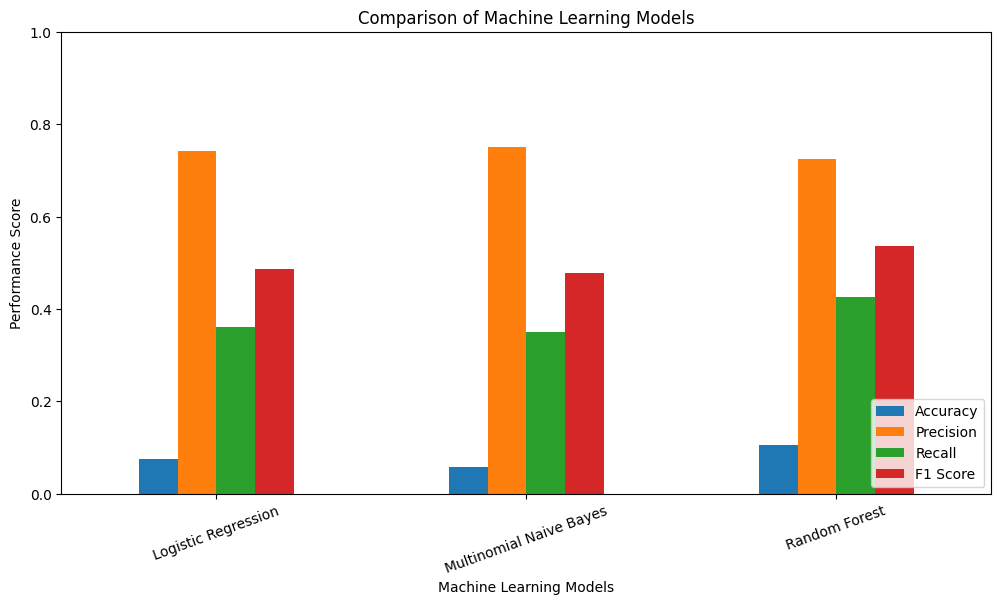

In [25]:
# Comparing the performance of all three models

results_plot = results_df.set_index('Model')

results_plot.plot(
    kind='bar',
    figsize=(12, 6)
)

plt.title("Comparison of Machine Learning Models")
plt.ylabel("Performance Score")
plt.xlabel("Machine Learning Models")
plt.xticks(rotation=20)
plt.legend(loc='lower right')
plt.ylim(0, 1)
plt.show()

In [26]:
# Finding the best value of C for Logistic Regression

lr_pipeline = Pipeline([

    ('tfidf', TfidfVectorizer(
        max_features=12000,
        ngram_range=(1, 2),
        stop_words='english',
        min_df=2,
        max_df=0.95
    )),

    ('classifier', OneVsRestClassifier(
        LogisticRegression(max_iter=2000)
    ))
])

# Testing different values of C
param_grid = {
    'classifier__estimator__C': [0.5, 1.0, 2.0]
}

# Applying Grid Search
grid_search = GridSearchCV(
    lr_pipeline,
    param_grid,
    cv=3,
    scoring='f1_micro',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross Validation F1 Score:")
print(grid_search.best_score_)

Fitting 3 folds for each of 3 candidates, totalling 9 fits
Best Parameters:
{'classifier__estimator__C': 2.0}

Best Cross Validation F1 Score:
0.5146199407813076


In [27]:
# Comparing the validation performance of all models

best_model_name = results_df.loc[
    results_df['F1 Score'].idxmax(), 'Model'
]

best_model = trained_models[best_model_name]

best_validation_f1 = results_df['F1 Score'].max()

# Checking whether tuned Logistic Regression performs better
tuned_val_predictions = grid_search.predict(X_val)

tuned_val_f1 = f1_score(
    y_val,
    tuned_val_predictions,
    average='micro',
    zero_division=0
)

if tuned_val_f1 > best_validation_f1:

    best_model = grid_search.best_estimator_
    best_model_name = "Tuned Logistic Regression"

print("Selected Best Model:", best_model_name)
print("Validation F1 Score:", max(best_validation_f1, tuned_val_f1))

Selected Best Model: Random Forest
Validation F1 Score: 0.5373134328358209


In [28]:
# Testing the selected model on unseen testing data

if best_model_name == "Tuned Logistic Regression":

    y_test_pred = best_model.predict(X_test)

else:

    y_test_pred = best_model.predict(X_test_tfidf)

# Calculating final performance
final_accuracy = accuracy_score(y_test, y_test_pred)

final_precision = precision_score(
    y_test, y_test_pred,
    average='micro',
    zero_division=0
)

final_recall = recall_score(
    y_test, y_test_pred,
    average='micro',
    zero_division=0
)

final_f1 = f1_score(
    y_test, y_test_pred,
    average='micro',
    zero_division=0
)

print("Final Model:", best_model_name)
print("--------------------------------")

print("Exact Match Accuracy:", final_accuracy)
print("Precision:", final_precision)
print("Recall:", final_recall)
print("F1 Score:", final_f1)

Final Model: Random Forest
--------------------------------
Exact Match Accuracy: 0.10869565217391304
Precision: 0.69
Recall: 0.43670886075949367
F1 Score: 0.5348837209302325


In [29]:
# Generating a detailed classification report

print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=mlb.classes_,
        zero_division=0
    )
)

              precision    recall  f1-score   support

      Action       0.77      0.44      0.56       128
   Adventure       0.00      0.00      0.00        19
   Biography       0.00      0.00      0.00        13
      Comedy       0.47      0.17      0.25       101
       Crime       0.60      0.44      0.51        75
       Drama       0.70      0.95      0.81       219
      Family       0.00      0.00      0.00        16
     Fantasy       0.00      0.00      0.00         7
     History       0.00      0.00      0.00         3
      Horror       1.00      0.08      0.15        12
       Music       0.00      0.00      0.00         2
     Musical       0.00      0.00      0.00        21
     Mystery       0.00      0.00      0.00        18
     Romance       0.82      0.35      0.49        81
      Sci-Fi       0.00      0.00      0.00         5
       Sport       0.00      0.00      0.00         8
    Thriller       0.50      0.02      0.03        62

   micro avg       0.69   

In [30]:
# Giving a new movie description to test our model

new_movie = [
    "A young boy discovers magical powers and goes on an adventure "
    "to save his family and the world."
]

# Making prediction using the selected model
if best_model_name == "Tuned Logistic Regression":

    predicted_genres = best_model.predict(new_movie)

else:

    new_movie_tfidf = tfidf.transform(new_movie)

    predicted_genres = best_model.predict(new_movie_tfidf)

# Converting numerical output into genre names
predicted_genre_names = mlb.inverse_transform(predicted_genres)

print("Movie Description:")
print(new_movie[0])

print("\nPredicted Movie Genres:")
print(predicted_genre_names[0])

Movie Description:
A young boy discovers magical powers and goes on an adventure to save his family and the world.

Predicted Movie Genres:
('Drama',)


In [31]:
# Saving the selected model and required information

model_data = {

    'model': best_model,

    'tfidf': tfidf,

    'genre_classes': mlb.classes_,

    'model_name': best_model_name,

    'problem_type': 'Multi-label Classification',

    'input_feature': 'Movie Overview'

}

# Saving the model file
joblib.dump(
    model_data,
    'movie_genre_prediction_model.joblib'
)

print("Model saved successfully!")

Model saved successfully!


In [32]:
# Downloading the trained model

from google.colab import files

files.download('movie_genre_prediction_model.joblib')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>